In [33]:
import numpy as np, cv2, tensorflow as tf
import glob, os
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight


#loading the dataset
root = "./simpsons_dataset"

characters = [k.split('/')[2] for k in glob.glob('./characters/*') if len([p for p in glob.glob(k+'/*') if 'edited' in p or 'pic_vid' in p]) > 290]
map_characters = dict(enumerate(characters))
map_characters = {0: 'abraham_grampa_simpson', 1: 'apu_nahasapeemapetilon', 2: 'bart_simpson',
        3: 'charles_montgomery_burns', 4: 'chief_wiggum', 5: 'comic_book_guy', 6: 'edna_krabappel',
        7: 'homer_simpson', 8: 'kent_brockman', 9: 'krusty_the_clown', 10: 'lisa_simpson',
        11: 'marge_simpson', 12: 'milhouse_van_houten', 13: 'moe_szyslak',
        14: 'ned_flanders', 15: 'nelson_muntz', 16: 'principal_skinner', 17: 'sideshow_bob'}

root = "./simpsons_dataset"

n_files = []

# Verify that images are found before training
for label, name in map_characters.items():
    files = glob.glob(os.path.join(root, name, "*"))
    n_files.append(len(files))
    print(f"{name}: {len(files)} files found")

print(n_files)

abraham_grampa_simpson: 913 files found
apu_nahasapeemapetilon: 623 files found
bart_simpson: 1342 files found
charles_montgomery_burns: 1193 files found
chief_wiggum: 986 files found
comic_book_guy: 469 files found
edna_krabappel: 457 files found
homer_simpson: 2246 files found
kent_brockman: 498 files found
krusty_the_clown: 1206 files found
lisa_simpson: 1354 files found
marge_simpson: 1291 files found
milhouse_van_houten: 1079 files found
moe_szyslak: 1452 files found
ned_flanders: 1454 files found
nelson_muntz: 358 files found
principal_skinner: 1194 files found
sideshow_bob: 877 files found
[913, 623, 1342, 1193, 986, 469, 457, 2246, 498, 1206, 1354, 1291, 1079, 1452, 1454, 358, 1194, 877]


<Axes: >

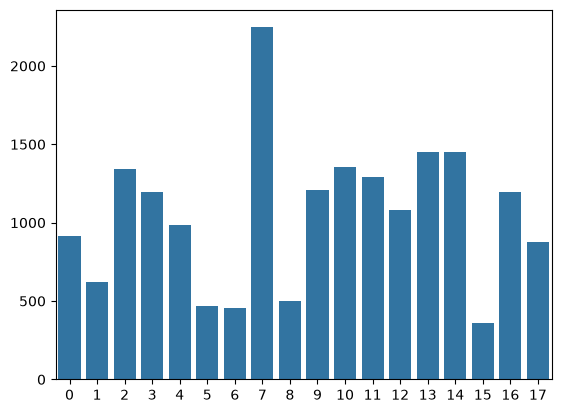

In [52]:
import matplotlib as plt
import seaborn as sns
from pathlib import Path

sns.barplot(n_files)



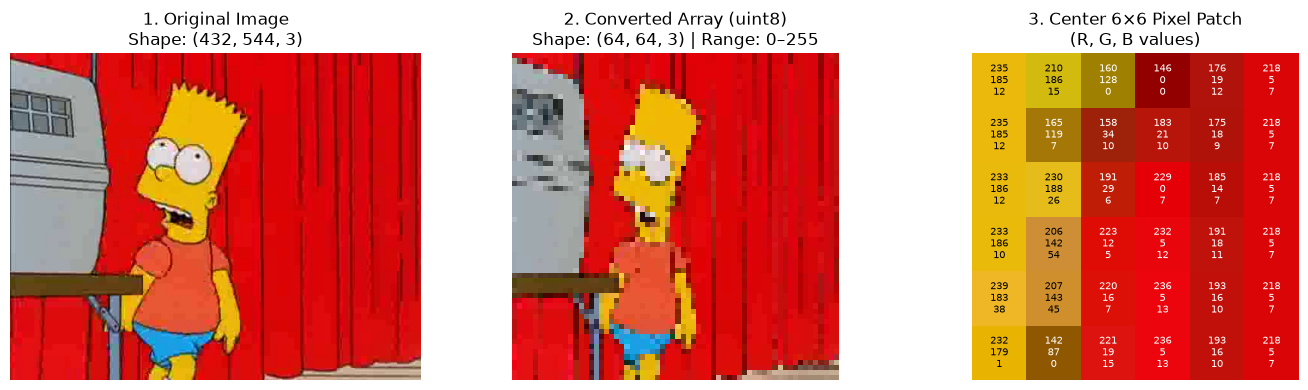

Sample top-left pixel (uint8 0-255): [193  23  26]
Sample top-left pixel (normalized 0-1): [0.757 0.09  0.102]


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

def visualize_conversion(image_path, img_size=64):
    orig_img = tf.keras.utils.load_img(image_path)
    orig_arr = tf.keras.utils.img_to_array(orig_img, dtype="uint8")

    #Load and convert to the 64x64 array stored in X
    resized_img = tf.keras.utils.load_img(image_path, target_size=(img_size, img_size))
    resized_arr = tf.keras.utils.img_to_array(resized_img, dtype="uint8")

    norm_arr = resized_arr.astype("float32") / 255.0

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    axes[0].imshow(orig_arr)
    axes[0].set_title(f"1. Original Image\nShape: {orig_arr.shape}")
    axes[0].axis("off")

    axes[1].imshow(resized_arr)
    axes[1].set_title(f"2. Converted Array (uint8)\nShape: {resized_arr.shape} | Range: 0–255")
    axes[1].axis("off")

    # Zoom into a 6x6 patch of pixels at the center to show actual RGB numbers
    center = img_size // 2
    patch = resized_arr[center-3:center+3, center-3:center+3]
    axes[2].imshow(patch)
    axes[2].set_title("3. Center 6×6 Pixel Patch\n(R, G, B values)")
    for i in range(6):
        for j in range(6):
            r, g, b = patch[i, j]
            text_color = "white" if (int(r) + int(g) + int(b)) < 380 else "black"
            axes[2].text(j, i, f"{r}\n{g}\n{b}", ha="center", va="center",
                         color=text_color, fontsize=7)
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

    print("Sample top-left pixel (uint8 0-255):", resized_arr[0, 0])
    print("Sample top-left pixel (normalized 0-1):", np.round(norm_arr[0, 0], 3))

# Example: test on Bart's image
visualize_conversion("./simpsons_dataset/bart_simpson/pic_0011.jpg")


In [ ]:
root = "./simpsons_dataset"
IMG_SIZE = 64
BATCH_SIZE = 64 
MAX_PER_CLASS = 1000 

X, y = [], []
for label, name in map_characters.items():
    paths = glob.glob(os.path.join(root, name, "*"))
    np.random.seed(42)
    np.random.shuffle(paths)
    
    for path in paths[:MAX_PER_CLASS]:
        try:
            img = tf.keras.utils.load_img(path, target_size=(IMG_SIZE, IMG_SIZE))
            # Store as uint8 (0-255)
            X.append(tf.keras.utils.img_to_array(img, dtype="uint8"))
            y.append(label)
        except Exception:
            continue

X = np.array(X, dtype="uint8")
y = np.array(y, dtype="int32")
print(f"Loaded {len(X)} images across {len(map_characters)} characters.")

# Stratified split
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Balance classes so common characters (Homer/Bart) don't dominate
weights = compute_class_weight("balanced", classes=np.unique(y_tr), y=y_tr) 
class_weights = dict(enumerate(weights)) #Assign bigger weight to characters with fewer images

#data pipelines
AUTOTUNE = tf.data.AUTOTUNE
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_tr, y_tr))
    .shuffle(4000, seed=42)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE) #preload the next batch while gpu is training
)


val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

model = models.Sequential([
    layers.Input((IMG_SIZE, IMG_SIZE, 3)),
    
    # Normalize 0-255 -> 0-1
    layers.Rescaling(1.0 / 255),
    
    # Augmentation handles off-center crops
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),

    # Block 1
    layers.Conv2D(32, 3, padding="same"),
    layers.Activation("relu"),
    layers.Conv2D(32, 3, padding="same"),
    layers.Activation("relu"),
    layers.Conv2D(32, 3),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.2),

    # Block 2
    layers.Conv2D(64, 3, padding="same"),
    layers.Activation("relu"),
    layers.Conv2D(64, 3, padding="same"),
    layers.Activation("relu"),
    layers.Conv2D(32, 3),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.3), #randomly turn off neurons to force rely on multiple features

    # Block 3
    layers.Conv2D(128, 3, padding="same"),
    layers.Activation("relu"),
    layers.Conv2D(128, 3, padding="same"),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.4),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(len(map_characters), activation="softmax"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.5*1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=26,
    class_weight=class_weights,
)


Loaded 15181 images across 18 characters.
Epoch 1/26


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


190/190 ━━━━━━━━━━━━━━━━━━━━ 46s 237ms/step - accuracy: 0.0763 - loss: 2.8586 - val_accuracy: 0.2038 - val_loss: 2.6051
Epoch 2/26
190/190 ━━━━━━━━━━━━━━━━━━━━ 47s 247ms/step - accuracy: 0.2150 - loss: 2.5202 - val_accuracy: 0.3339 - val_loss: 2.1891
Epoch 3/26
190/190 ━━━━━━━━━━━━━━━━━━━━ 56s 296ms/step - accuracy: 0.2964 - loss: 2.2577 - val_accuracy: 0.4501 - val_loss: 1.8256
Epoch 4/26
190/190 ━━━━━━━━━━━━━━━━━━━━ 71s 373ms/step - accuracy: 0.3905 - loss: 1.9641 - val_accuracy: 0.5426 - val_loss: 1.5596
Epoch 5/26
190/190 ━━━━━━━━━━━━━━━━━━━━ 66s 347ms/step - accuracy: 0.4667 - loss: 1.7002 - val_accuracy: 0.5703 - val_loss: 1.3924
Epoch 6/26
190/190 ━━━━━━━━━━━━━━━━━━━━ 66s 345ms/step - accuracy: 0.5170 - loss: 1.5563 - val_accuracy: 0.6329 - val_loss: 1.2052
Epoch 7/26
190/190 ━━━━━━━━━━━━━━━━━━━━ 65s 343ms/step - accuracy: 0.5620 - loss: 1.3975 - val_accuracy: 0.6655 - val_loss: 1.1389
Epoch 8/26
190/190 ━━━━━━━━━━━━━━━━━━━━ 69s 366ms/step - accuracy: 0.5884 - loss: 1.3080 - val

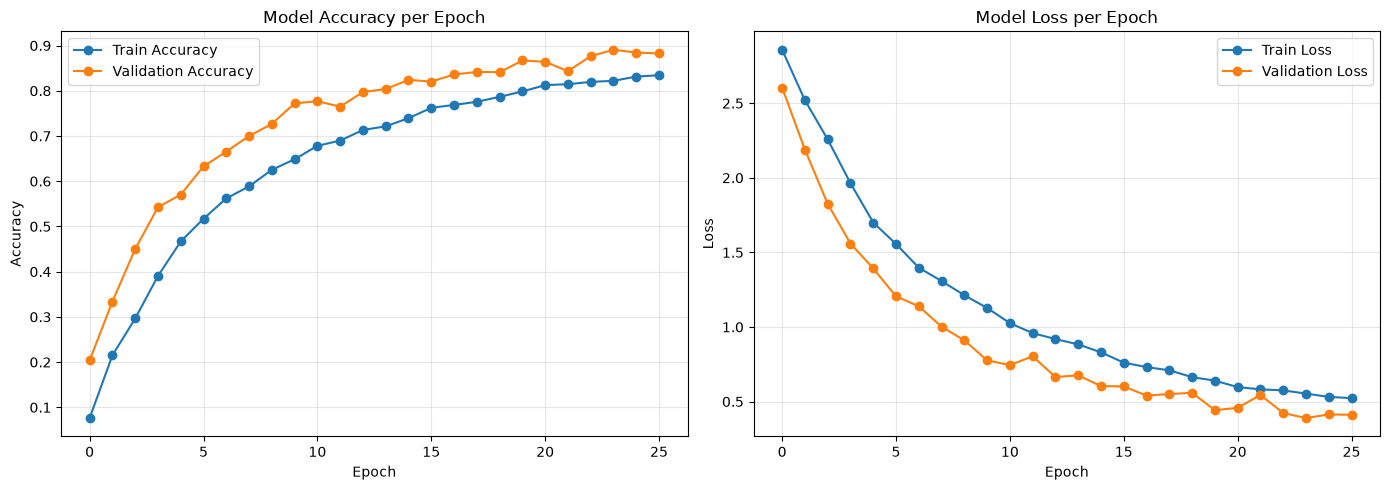

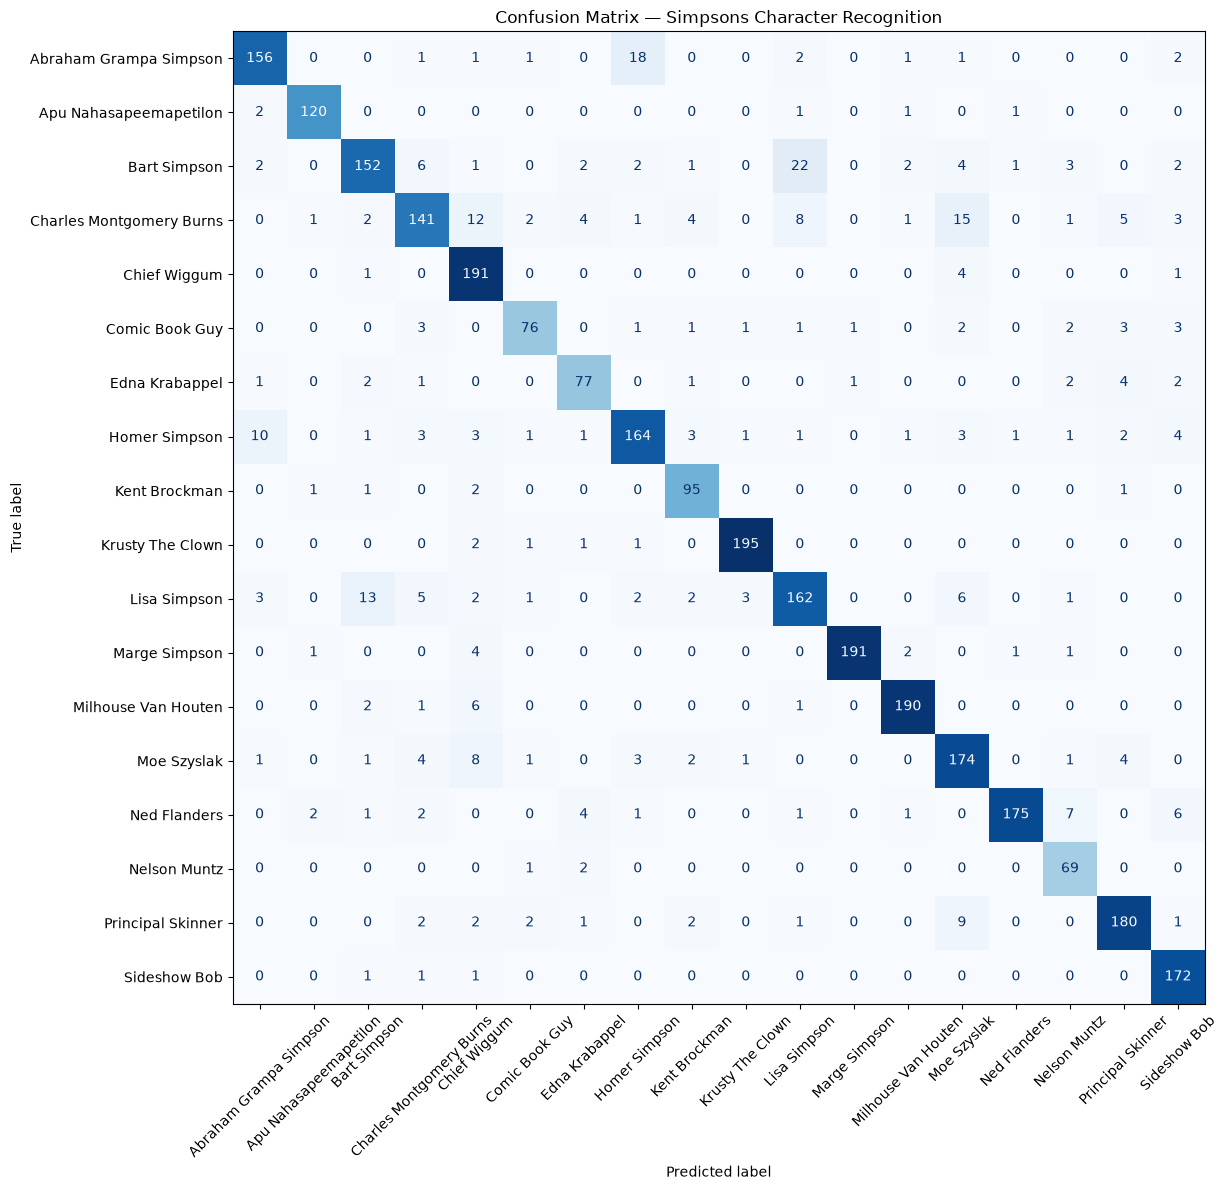

                          precision    recall  f1-score   support

  Abraham Grampa Simpson      0.891     0.852     0.872       183
  Apu Nahasapeemapetilon      0.960     0.960     0.960       125
            Bart Simpson      0.859     0.760     0.806       200
Charles Montgomery Burns      0.829     0.705     0.762       200
            Chief Wiggum      0.813     0.970     0.884       197
          Comic Book Guy      0.884     0.809     0.844        94
          Edna Krabappel      0.837     0.846     0.842        91
           Homer Simpson      0.850     0.820     0.835       200
           Kent Brockman      0.856     0.950     0.900       100
        Krusty The Clown      0.970     0.975     0.973       200
            Lisa Simpson      0.810     0.810     0.810       200
           Marge Simpson      0.990     0.955     0.972       200
     Milhouse Van Houten      0.955     0.950     0.952       200
             Moe Szyslak      0.798     0.870     0.833       200
         

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

#Plot Training & Validation Accuracy and Loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history["accuracy"], label="Train Accuracy", marker="o")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy", marker="o")
axes[0].set_title("Model Accuracy per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(history.history["loss"], label="Train Loss", marker="o")
axes[1].plot(history.history["val_loss"], label="Validation Loss", marker="o")
axes[1].set_title("Model Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- 2. Confusion Matrix on Validation Set ---
y_pred_probs = model.predict(val_ds, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Clean character names for readable axis labels
class_labels = [map_characters[i].replace("_", " ").title() for i in range(len(map_characters))]

cm = confusion_matrix(y_val, y_pred)
fig, ax = plt.subplots(figsize=(14, 12))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix — Simpsons Character Recognition")
plt.tight_layout()
plt.show()

#Precision per Character
print(classification_report(y_val, y_pred, target_names=class_labels, digits=3))


Loaded 890 test images matching your 18 trained classes.

Test Set Accuracy: 91.46%

                          precision    recall  f1-score   support

  Abraham Grampa Simpson      0.909     0.833     0.870        48
  Apu Nahasapeemapetilon      0.962     1.000     0.980        50
            Bart Simpson      0.808     0.840     0.824        50
Charles Montgomery Burns      0.837     0.750     0.791        48
            Chief Wiggum      0.889     0.960     0.923        50
          Comic Book Guy      0.917     0.898     0.907        49
          Edna Krabappel      0.940     0.940     0.940        50
           Homer Simpson      0.833     0.900     0.865        50
           Kent Brockman      0.943     1.000     0.971        50
        Krusty The Clown      1.000     1.000     1.000        50
            Lisa Simpson      0.929     0.780     0.848        50
           Marge Simpson      0.980     0.980     0.980        50
     Milhouse Van Houten      0.940     0.959     0.949 

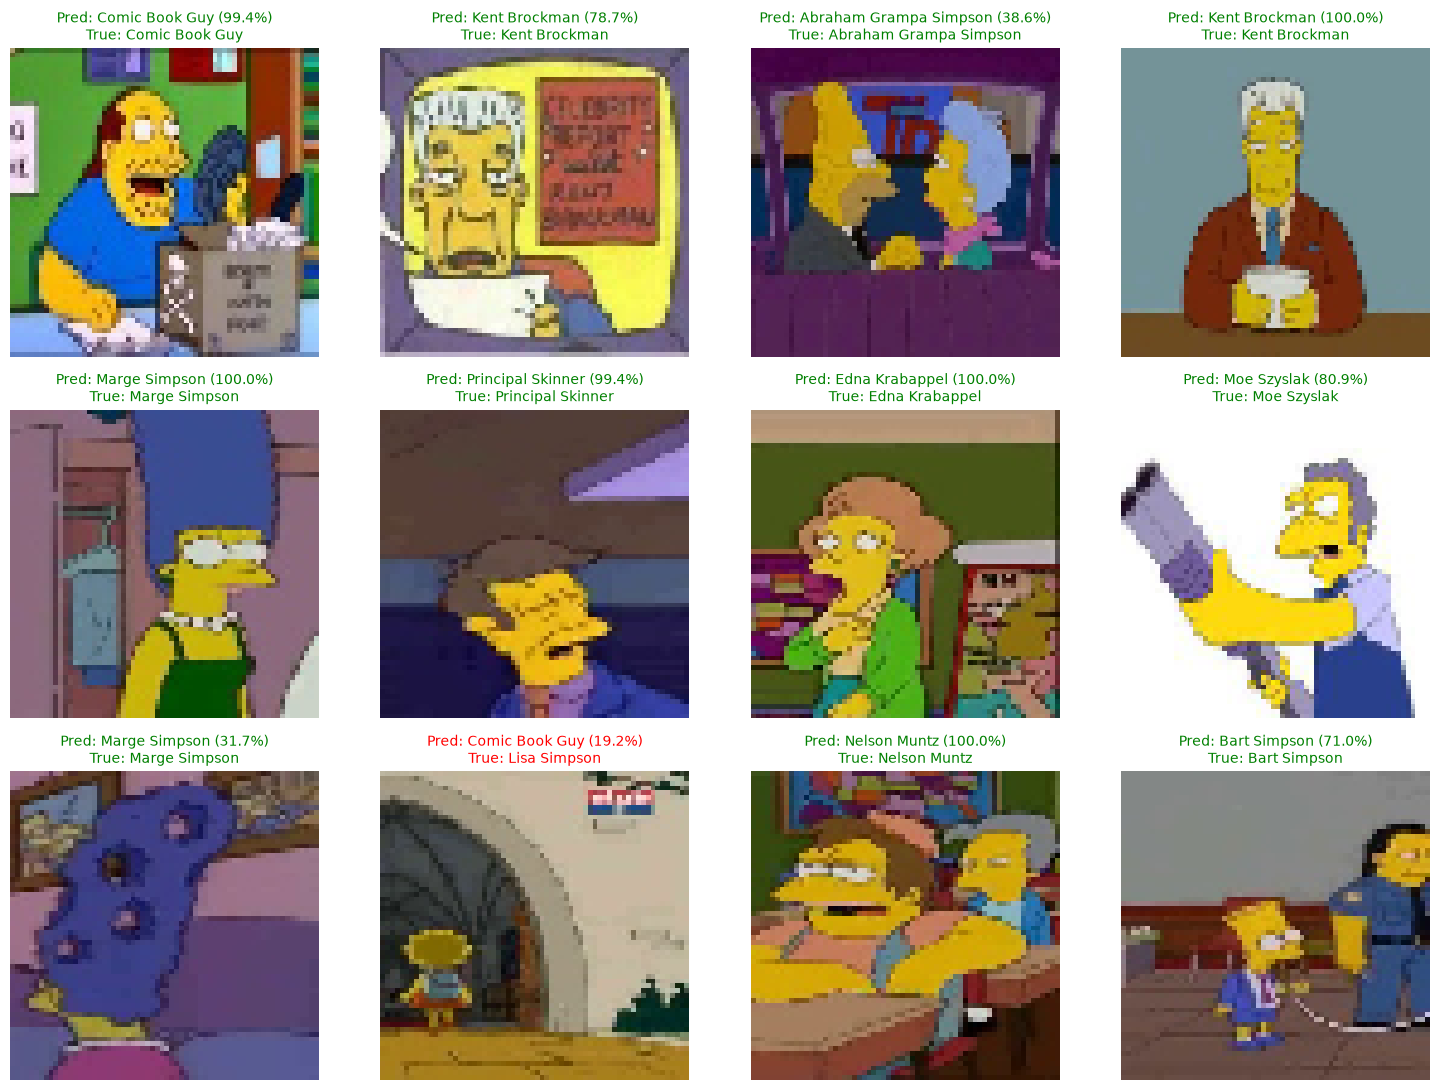

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

test_dir = "./kaggle_simpson_testset"

# Reverse mapping: 'abraham_grampa_simpson' -> 0, etc.
name_to_label = {name: label for label, name in map_characters.items()}

X_test, y_test, test_paths = [], [], []

for path in sorted(glob.glob(os.path.join(test_dir, "*.jpg"))):
    filename = os.path.basename(path)
    
    char_name = "_".join(filename.split("_")[:-1])
    
    # Only include characters the model was trained on
    if char_name not in name_to_label:
        continue
        
    try:
        img = tf.keras.utils.load_img(path, target_size=(IMG_SIZE, IMG_SIZE))
        X_test.append(tf.keras.utils.img_to_array(img, dtype="uint8"))
        y_test.append(name_to_label[char_name])
        test_paths.append(path)
    except Exception:
        continue

X_test = np.array(X_test, dtype="uint8")
y_test = np.array(y_test, dtype="int32")
print(f"Loaded {len(X_test)} test images matching your {len(map_characters)} trained classes.")

# 1. Run Predictions
y_test_probs = model.predict(X_test, batch_size=64, verbose=0)
y_test_pred = np.argmax(y_test_probs, axis=1) #model.predict returns an array of probabilities that sums to 1, therefore we need the max argument

# 2. Overall Test Accuracy & Per-Character Metrics
test_acc = accuracy_score(y_test, y_test_pred)
print(f"\nTest Set Accuracy: {test_acc * 100:.2f}%\n")

class_labels = [map_characters[i].replace("_", " ").title() for i in range(len(map_characters))]
print(classification_report(y_test, y_test_pred, target_names=class_labels, digits=3))

# 3. Visual Grid of 12 Sample Predictions
np.random.seed(42)
sample_idx = np.random.choice(len(X_test), size=min(12, len(X_test)), replace=False)

fig, axes = plt.subplots(3, 4, figsize=(15, 11))
for ax, idx in zip(axes.flat, sample_idx):
    ax.imshow(X_test[idx])
    true_name = map_characters[y_test[idx]].replace("_", " ").title()
    pred_name = map_characters[y_test_pred[idx]].replace("_", " ").title()
    conf = y_test_probs[idx][y_test_pred[idx]] * 100
    
    is_correct = y_test[idx] == y_test_pred[idx]
    color = "green" if is_correct else "red"
    ax.set_title(f"Pred: {pred_name} ({conf:.1f}%)\nTrue: {true_name}", color=color, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

#the worst possible accuracy would be 1/17 = 5.88%
